# Wind correction

The metamodel cases (notebook 05) run **without wind**. The reconstruction
(`mm.reconstruct(..., wind_correction=True)`) adds the local wind sea once per
time step and site, before the goals' spectra are summed:

- contributions whose *offshore* forcing is a wind sea (steep, broad; weight
  `w` from `metamodel.wind_correction.steepness_range` / `spr_range`) give the
  wind-sea energy at the site, `E_ws = Σ w·hs²`;
- `K = Hs(with wind) / Hs(without wind)` comes from a model fitted here, on
  dimensionless wind-sea Hs, fetch and depth (`g·X/U²`) and the wind-wave angle;
- one extra contribution, `(K² − 1)·E_ws` from the wind direction, joins the sum.

Workflow:

1. **Fetch table**: fetch and mean depth along it per output site and wind
   direction, over the model grid (`outputs/wind/fetch_table_{model}.nc`).
2. **Training cases**: `num_cases` full-domain wind seas (every goal forced the
   same), each with a wind of `speed_ratio` × the fully developed speed blowing
   `wind_wave_angle` off the waves; built twice, with and without wind, with
   the model's dynamic templates (`simulations.<model>.wind_cases`).
3. Run them (on the cluster), postprocess.
4. **Fit** `K`, score it on held-out cases, save
   (`outputs/wind/wind_correction_{model}.pkl`).

Set `metamodel.wind_correction.enabled = true` to use it by default in 09–12.

In [1]:
import os
import sys

# Must run before any GDAL-touching import (geopandas/pyogrio, rasterio/rioxarray).
# When the kernel is launched without going through `conda activate` (e.g. VS
# Code's Jupyter extension), GDAL_DATA/PROJ_DATA are unset, and importing
# rioxarray/rasterio before geopandas.read_file() in that state leaves GDAL's
# data-path auto-discovery broken for pyogrio, raising:
#   ValueError: Found GDAL data directory at .../share/gdal but it does not
#   appear to correctly contain GDAL data files
# Setting these explicitly sidesteps the broken auto-discovery.
os.environ.setdefault("GDAL_DATA", os.path.join(sys.prefix, "share", "gdal"))
os.environ.setdefault("PROJ_DATA", os.path.join(sys.prefix, "share", "proj"))

import matplotlib.pyplot as plt
from utils import simulation as sim
from utils import wind
from utils.config import load_goals, simulation_model

In [2]:
model = simulation_model()
cfg = wind.config()
print(f"model      : {model}")
print(f"cases      : {wind.wind_cases_dir(True).parent}")
print(f"wind       : {cfg['wind']} (reconstruction), added Tp: {cfg['added_tp']}")
print(
    f"design     : {cfg['num_cases']} cases, U/U_fd {cfg['speed_ratio']}, angle {cfg['wind_wave_angle']}"
)
print(f"wind sea   : steepness {cfg['steepness_range']}, spr {cfg['spr_range']}")

model      : snapwave
cases      : /lustre/geocean/WORK/users/javiert/projects/HyGloW/Netherlands/SnapWave_CASES_Wind
wind       : forcing (reconstruction), added Tp: wind_sea
design     : 100 cases, U/U_fd [0.8, 2.0], angle [-60.0, 60.0]
wind sea   : steepness [0.02, 0.03], spr [20.0, 25.0]


## 1 · Fetch table

In [3]:
table = wind.fetch_table()  # cached; recompute=True after changing sites or grid
table

<xarray.Dataset> Size: 746kB
Dimensions:     (sites: 407, dir: 72)
Coordinates:
  * sites       (sites) object 3kB '5m_0' '5m_1' ... 'buoy_zdv8-2d-MMND'
    point_x     (sites) float64 3kB 6.777 6.789 6.864 6.923 ... 6.367 3.42 4.01
    point_y     (sites) float64 3kB 53.64 53.68 53.68 ... 53.62 51.43 51.99
  * dir         (dir) float64 576B 0.0 5.0 10.0 15.0 ... 340.0 345.0 350.0 355.0
Data variables:
    fetch       (sites, dir) float64 234kB 3.925e+04 3.95e+04 ... 9.9e+04
    mean_depth  (sites, dir) float64 234kB 19.75 19.68 19.49 ... 24.73 23.91
    open_exit   (sites, dir) bool 29kB True True True True ... True True True
    site_depth  (sites) float64 3kB 7.715 4.333 5.493 ... 14.88 13.55 16.03
    fetch_eff   (sites, dir) float64 234kB 3.591e+04 3.458e+04 ... 9.359e+04
Attributes:
    step:          250.0
    max_distance:  500000.0
    model:         snapwave
    grid:          inputs/GRID/Netherlands_mesh.nc

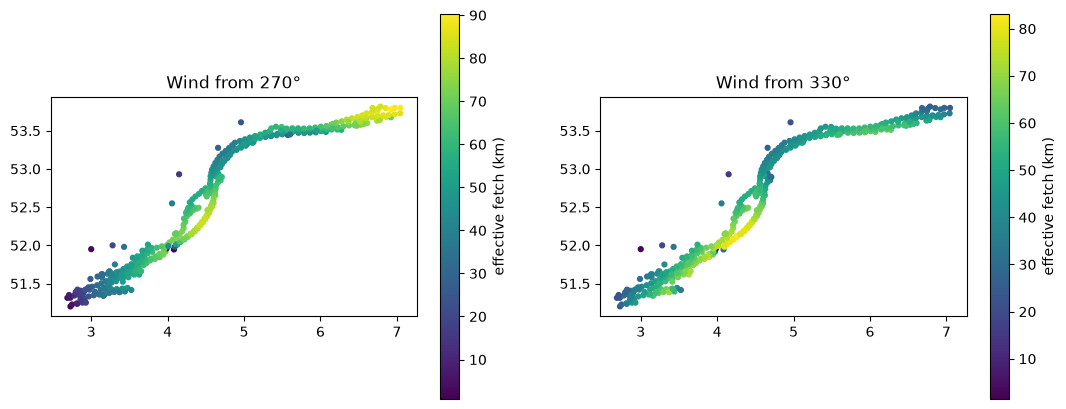

sites outside the grid (no correction): 39


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, direction in zip(axes, (270.0, 330.0)):
    sc = ax.scatter(
        table["point_x"],
        table["point_y"],
        c=table["fetch_eff"].sel(dir=direction) / 1e3,
        s=12,
        cmap="viridis",
    )
    plt.colorbar(sc, ax=ax, label="effective fetch (km)")
    ax.set_title(f"Wind from {direction:.0f}°")
    ax.set_aspect("equal")
plt.show()
print(f"sites outside the grid (no correction): {int(table.site_depth.isnull().sum())}")

## 2 · Training cases (with and without wind)

In [5]:
goals = load_goals()
cases = wind.generate_wind_cases(goals)
cases.describe().round(2)

,hs,tp,dir,spr,wl,speed_ratio,wind_wave_angle,ws_weight,u10,u10dir
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,4.74,8.58,189.23,33.82,0.01,1.40,0.88,0.89,18.69,175.71
std,2.50,3.09,101.14,6.86,2.27,0.35,34.98,0.17,7.78,106.01
min,0.31,2.39,4.14,22.54,-3.49,0.81,-59.70,0.50,3.65,0.07
25%,2.33,6.41,92.53,27.56,-2.09,1.12,-29.32,0.78,14.05,76.41
50%,4.96,8.66,201.04,33.37,0.07,1.36,0.88,1.00,18.35,176.99
75%,7.11,10.92,275.00,40.07,2.17,1.70,30.69,1.00,23.20,261.88
max,8.00,13.98,357.34,44.96,3.50,1.99,59.61,1.00,35.00,353.61


In [6]:
setup = sim.HyWavesWrapperSetup.from_case(goals)
wrappers = wind.wind_case_wrappers(setup, cases)  # also writes wind_cases.csv
for wrapper in wrappers.values():
    wrapper.build_cases()
# after a kernel restart: wrappers = wind.wind_case_wrappers(setup), then
# wrapper.load_cases() for each

## 3 · Run (by hand, on the cluster), postprocess

SnapWave with wind needs the `wind1` build (`simulations.snapwave.slurm.setup`),
`sector = 360` and `niter = 200` (set by the dynamic template when `u10 > 0`):
minutes per case instead of seconds. SWAN with wind (`GEN3`) is slower too.

In [7]:
wrappers["wind"].run_cases_slurm(
    **sim.slurm_kwargs(
        cpus_per_task=8, mem="16gb", extra_sbatch=["--time=06:00:00"], max_parallel=50
    )
)
wrappers["no_wind"].run_cases_slurm(**sim.slurm_kwargs(max_parallel=50))

Submitted batch job 860629
Submitted batch job 860630


In [14]:
for label, wrapper in wrappers.items():
    display(label, wrapper.monitor_cases(value_counts="simple"))

'wind'

Status  
FINISHED    100
Name: count, dtype: int64

'no_wind'

Status  
FINISHED    100
Name: count, dtype: int64

In [15]:
for label, wrapper in wrappers.items():
    wrapper.postprocess_cases().to_netcdf(wind.postprocessed_path(label == "wind"))

## 4 · Fit K

Scores: Hs on held-out training cases (reference = the run **with** wind),
without and with the correction.

In [16]:
correction, scores = wind.fit_wind_correction()
scores.pivot_table(index="group", columns="estimate", values=["bias", "rmse"]).round(3)

bias                          rmse                
estimate no correction wind correction no correction wind correction
group                                                               
10m             -0.311          -0.022         0.564           0.398
20m             -0.877          -0.203         1.112           0.557
5m              -0.070          -0.002         0.347           0.318
waves           -0.749          -0.189         1.163           0.694

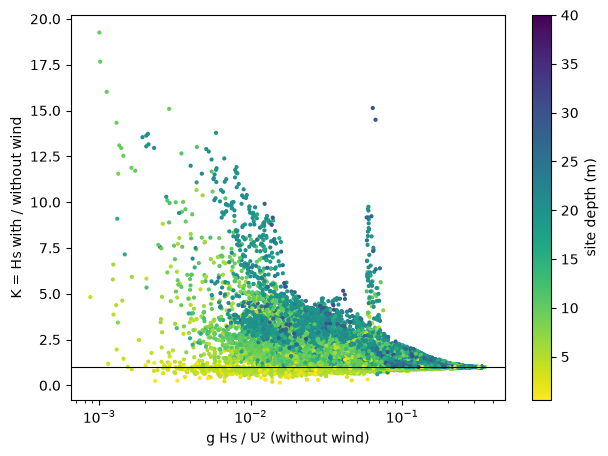

In [17]:
pairs = wind.training_pairs().dropna(subset=["hs0", "hs1"])
pairs = pairs[pairs["hs0"] > 0.1]
fig, ax = plt.subplots(figsize=(7, 5))
sc = ax.scatter(
    9.81 * pairs["hs0"] / pairs["u10"] ** 2,
    pairs["hs1"] / pairs["hs0"],
    c=pairs["depth"],
    s=4,
    cmap="viridis_r",
    vmax=40,
)
plt.colorbar(sc, label="site depth (m)")
ax.axhline(1, color="k", lw=0.8)
ax.set(
    xlabel="g Hs / U² (without wind)", ylabel="K = Hs with / without wind", xscale="log"
)
plt.show()